<a href="https://colab.research.google.com/github/nishithy13/DS2002-Midterm/blob/main/06-midterm-walmart/2026-10-28%20%E2%80%94%20Midterm%20Clinic%20Analysis%20and%20Charts%20%E2%80%94%20Studio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Clinic Analysis and Charts

**Studio — 2026-10-28 · Fall 2026**  
**Class time:** 45 minutes

---

## Clinic — analysis and charts

Working session on your own project. The patterns below are the four analytical moves Questions 1 through 4 need; adapt each one to your cleaned data.

By the end of the hour you should have at least two charts you would be willing to put in the presentation on Monday.

### Pattern 1 — products moving together before landfall

One line per product, landfall marked. This is the Q1 chart, and it is the one that carries your presentation.

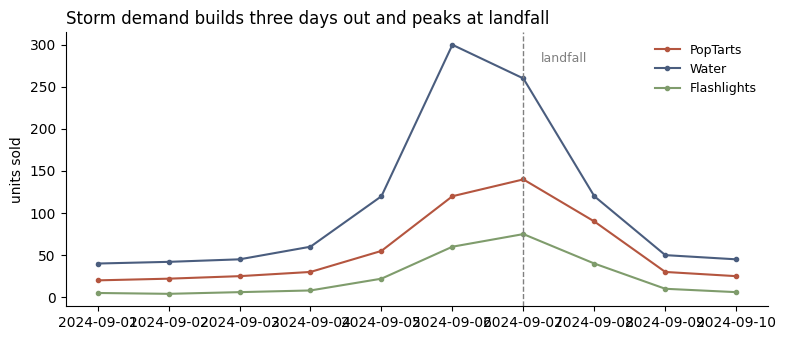

In [10]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

daily = pd.DataFrame({
    'date': pd.date_range('2024-09-01', periods=10),
    'PopTarts': [20, 22, 25, 30, 55, 120, 140, 90, 30, 25],
    'Water': [40, 42, 45, 60, 120, 300, 260, 120, 50, 45],
    'Flashlights': [5, 4, 6, 8, 22, 60, 75, 40, 10, 6],
}).set_index('date')
landfall = pd.Timestamp('2024-09-07')

fig, ax = plt.subplots(figsize=(8, 3.5))
for col, color in zip(daily.columns, ['#b4553f', '#4a5d7e', '#7f9c6c']):
    ax.plot(daily.index, daily[col], marker='o', ms=3, color=color, label=col)
ax.axvline(landfall, ls='--', color='gray', lw=1)
ax.annotate('landfall', xy=(landfall + pd.Timedelta(hours=6), 280),
            fontsize=9, color='gray')
ax.set_title('Storm demand builds three days out and peaks at landfall',
             loc='left', fontsize=12)
ax.set_ylabel('units sold')
ax.legend(frameon=False, fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

**TODO:** rebuild that with your own cleaned categories and your own landfall date. Title it with what your data actually shows — if your surge peaks a day early, say that.

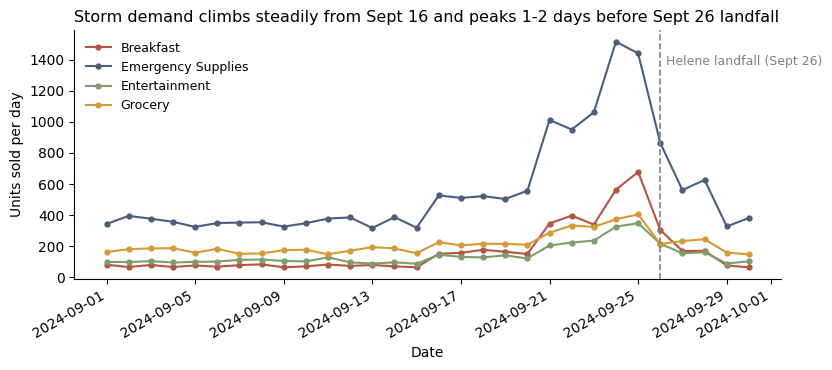

In [11]:
# TODO
# TODO
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Locate data folder whether running in root, 06-midterm-walmart/, notebooks/, or Colab
def find_data(filename, folders=('data', '../data', '06-midterm-walmart/data', '../06-midterm-walmart/data',
                                '/content/DS2002-Midterm/data', '/content/DS2002-Midterm/06-midterm-walmart/data')):
    for folder in folders:
        path = os.path.join(folder, filename)
        if os.path.exists(path):
            return path
    if os.path.exists('/content'):
        os.system('git clone https://github.com/nishithy13/DS2002-Midterm.git /content/DS2002-Midterm 2>/dev/null')
        for folder in ('/content/DS2002-Midterm/data', '/content/DS2002-Midterm/06-midterm-walmart/data'):
            path = os.path.join(folder, filename)
            if os.path.exists(path):
                return path
    raise FileNotFoundError(f'Could not find {filename}')

# 1. Clean transactions using Monday clinic patterns
tx_raw = pd.read_csv(find_data('walmart_transactions.csv'))
cat_df = pd.read_csv(find_data('product_catalog.csv'))
stores_df = pd.read_csv(find_data('store_locations.csv'))

tx = tx_raw.drop_duplicates().copy()
tx['unit_price'] = pd.to_numeric(tx['unit_price'].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False).str.strip(), errors='coerce')
tx['quantity'] = pd.to_numeric(tx['quantity'], errors='coerce')
tx = tx[(tx['unit_price'] > 0) & (tx['quantity'] > 0)].copy()

tx['timestamp'] = pd.to_datetime(tx['timestamp'], errors='coerce', format='mixed')
tx = tx[tx['timestamp'].notna()].copy()
tx['date'] = tx['timestamp'].dt.normalize()

tx['store_id'] = (tx['store_id'].astype(str).str.upper().str.strip()
                  .str.replace(r'[^A-Z0-9]', '', regex=True)
                  .apply(lambda s: f'{s[:2]}-{s[2:]}' if len(s) > 2 else s))

# 2. Consolidate SKUs via normalized product_name mapping table
sku_pool = pd.concat([cat_df[['sku', 'product_name']], tx[['sku', 'product_name']].dropna()], ignore_index=True).drop_duplicates('sku')
sku_pool['norm_key'] = (sku_pool['product_name'].astype(str).str.lower()
                        .str.replace(r'[^a-z0-9 ]', ' ', regex=True)
                        .str.replace(r'\bpoptart\b', 'poptarts', regex=True)
                        .str.replace(r'\bpack\b', 'pk', regex=True)
                        .str.split().apply(lambda w: ' '.join(sorted(w))))

canon_lookup = sku_pool.groupby('norm_key').agg(
    canonical_sku=('sku', lambda s: sorted(s.astype(str))[0]),
    canonical_name=('product_name', 'first')
).reset_index()
mapping_table = sku_pool[['sku', 'norm_key']].merge(canon_lookup, on='norm_key', how='left').drop_duplicates('sku')

tx = tx.merge(mapping_table[['sku', 'canonical_sku', 'canonical_name']], on='sku', how='left', validate='many_to_one')
tx['canonical_sku'] = tx['canonical_sku'].fillna(tx['sku'])
tx['canonical_name'] = tx['canonical_name'].fillna(tx['product_name'])

# Standardize category using catalog where possible
if 'category' in cat_df.columns:
    cat_map = cat_df.drop_duplicates('sku').set_index('sku')['category'].str.strip().str.title().to_dict()
    tx['clean_category'] = tx['canonical_sku'].map(cat_map).fillna(tx['category'].astype(str).str.strip().str.title())
else:
    tx['clean_category'] = tx['category'].astype(str).str.strip().str.title()

tx['clean_category'] = tx['clean_category'].replace({'Breakfast Foods': 'Breakfast', 'Emergency': 'Emergency Supplies'})

# 3. Build daily category table across top 4 categories
LANDFALL = pd.Timestamp('2024-09-26')
top_cats = tx.groupby('clean_category')['quantity'].sum().nlargest(4).index.tolist()
daily_cat = (tx[tx['clean_category'].isin(top_cats)]
             .groupby(['date', 'clean_category'])['quantity'].sum()
             .unstack(fill_value=0)
             .sort_index())

colors = ['#b4553f', '#4a5d7e', '#7f9c6c', '#d49a35']
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for col, color in zip(daily_cat.columns, colors):
    ax.plot(daily_cat.index, daily_cat[col], marker='o', ms=3.5, color=color, label=col)

ax.axvline(LANDFALL, ls='--', color='gray', lw=1.2)
ax.annotate('Helene landfall (Sept 26)', xy=(LANDFALL + pd.Timedelta(hours=6), daily_cat.max().max() * 0.9),
            fontsize=9, color='gray')
ax.set_title('Storm demand climbs steadily from Sept 16 and peaks 1-2 days before Sept 26 landfall',
             loc='left', fontsize=11.5)
ax.set_ylabel('Units sold per day')
ax.set_xlabel('Date')
ax.legend(frameon=False, fontsize=9, loc='upper left')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

### Pattern 2 — indexing to baseline so different products are comparable

Water outsells flashlights ten to one, so on a raw chart the flashlight surge is invisible. Divide each series by its own pre-storm average and every product starts at 1.0 — now you are comparing *how much each one moved*, which is the actual question.

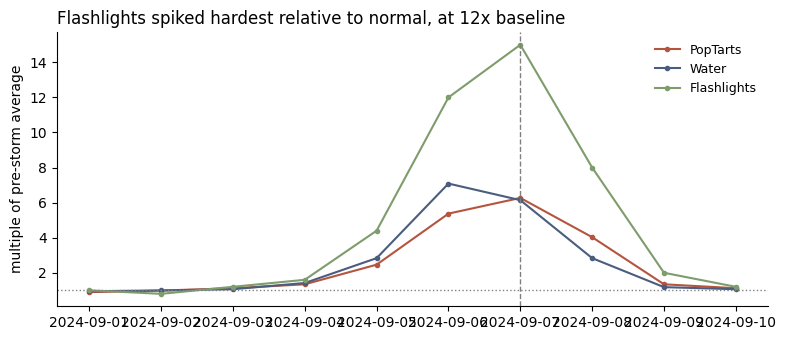

Flashlights    15.0
Water           7.1
PopTarts        6.3
dtype: float64


In [12]:
baseline = daily[daily.index < landfall - pd.Timedelta(days=3)].mean()
indexed = daily / baseline

fig, ax = plt.subplots(figsize=(8, 3.5))
for col, color in zip(indexed.columns, ['#b4553f', '#4a5d7e', '#7f9c6c']):
    ax.plot(indexed.index, indexed[col], marker='o', ms=3, color=color, label=col)
ax.axhline(1.0, ls=':', color='gray', lw=1)
ax.axvline(landfall, ls='--', color='gray', lw=1)
ax.set_title('Flashlights spiked hardest relative to normal, at 12x baseline',
             loc='left', fontsize=12)
ax.set_ylabel('multiple of pre-storm average')
ax.legend(frameon=False, fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print(indexed.max().round(1).sort_values(ascending=False))

Two charts, same data, different findings. The raw chart says water is the story; the indexed chart says flashlights are. Both belong in the presentation, in that order.

**TODO:** index your own products to their baseline and see whether your ranking changes.

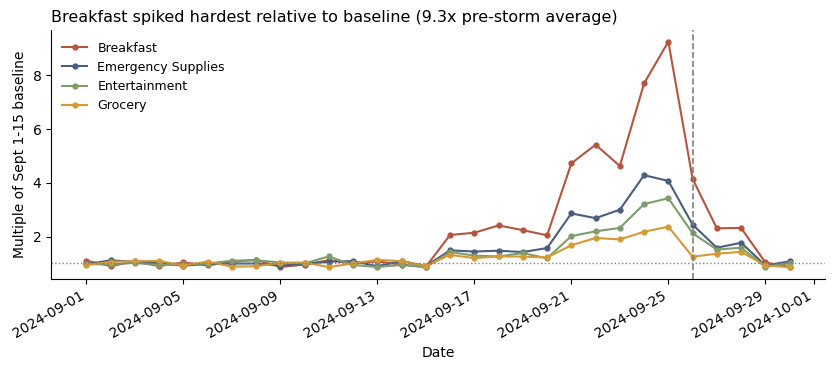

Peak category multiples vs Sept 1-15 baseline:
clean_category
Breakfast             9.25
Emergency Supplies    4.28
Entertainment         3.43
Grocery               2.37
dtype: float64

Top 5 canonical products (Sept 23-25 surge avg vs Sept 1-15 baseline avg):
canonical_name
pop-tarts strawberry    7.22
Strawberry Pop-Tart     7.10
BATTERIES AA 4PK        4.17
FLASHLIGHT LED          4.11
Heavy Duty Tarp         3.97
dtype: float64


In [13]:
# TODO
# TODO
# Baseline window: Sept 1-15 (flat normal period before the Sept 16 rise)
baseline_cat = daily_cat[(daily_cat.index >= '2024-09-01') & (daily_cat.index <= '2024-09-15')].mean()
indexed_cat = daily_cat / baseline_cat

top_cat_mover = indexed_cat.max().idxmax()
top_cat_mult = indexed_cat.max().max()

fig, ax = plt.subplots(figsize=(8.5, 3.8))
for col, color in zip(indexed_cat.columns, ['#b4553f', '#4a5d7e', '#7f9c6c', '#d49a35']):
    ax.plot(indexed_cat.index, indexed_cat[col], marker='o', ms=3.5, color=color, label=col)

ax.axhline(1.0, ls=':', color='gray', lw=1)
ax.axvline(LANDFALL, ls='--', color='gray', lw=1.2)
ax.set_title(f'{top_cat_mover} spiked hardest relative to baseline ({top_cat_mult:.1f}x pre-storm average)',
             loc='left', fontsize=11.5)
ax.set_ylabel('Multiple of Sept 1-15 baseline')
ax.set_xlabel('Date')
ax.legend(frameon=False, fontsize=9, loc='upper left')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

print('Peak category multiples vs Sept 1-15 baseline:')
print(indexed_cat.max().round(2).sort_values(ascending=False))

# Also compute product-level surge multiple (Sept 23-25 surge window vs Sept 1-15 baseline) for the Checkpoint
daily_prod = tx.groupby(['date', 'canonical_name'])['quantity'].sum().unstack(fill_value=0)
prod_base = daily_prod[(daily_prod.index >= '2024-09-01') & (daily_prod.index <= '2024-09-15')].mean()
prod_base = prod_base[prod_base > 0]
prod_surge_3d = daily_prod[(daily_prod.index >= '2024-09-23') & (daily_prod.index <= '2024-09-25')][prod_base.index].mean()
prod_multiples_3d = (prod_surge_3d / prod_base).sort_values(ascending=False)

print('\nTop 5 canonical products (Sept 23-25 surge avg vs Sept 1-15 baseline avg):')
print(prod_multiples_3d.head(5).round(2))

### Pattern 3 — before-and-after for Q2

The SKU consolidation question needs a comparison, not a description. Show the number somebody would have reported without your work next to the number with it.

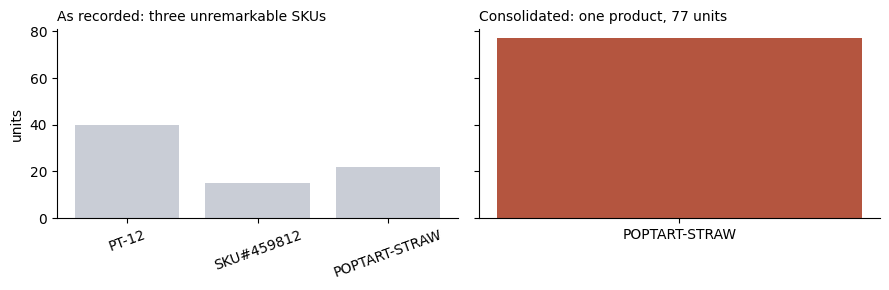

In [14]:
fragmented = pd.Series({'PT-12': 40, 'SKU#459812': 15, 'POPTART-STRAW': 22})
consolidated = pd.Series({'POPTART-STRAW': 77})

fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
axes[0].bar(fragmented.index, fragmented.values, color='#c9cdd6')
axes[0].set_title('As recorded: three unremarkable SKUs', fontsize=10, loc='left')
axes[0].tick_params(axis='x', labelrotation=20)
axes[1].bar(consolidated.index, consolidated.values, color='#b4553f')
axes[1].set_title('Consolidated: one product, 77 units', fontsize=10, loc='left')
axes[0].set_ylabel('units')
for ax in axes:
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

**TODO:** build this for your largest consolidated product family. State the multiple.

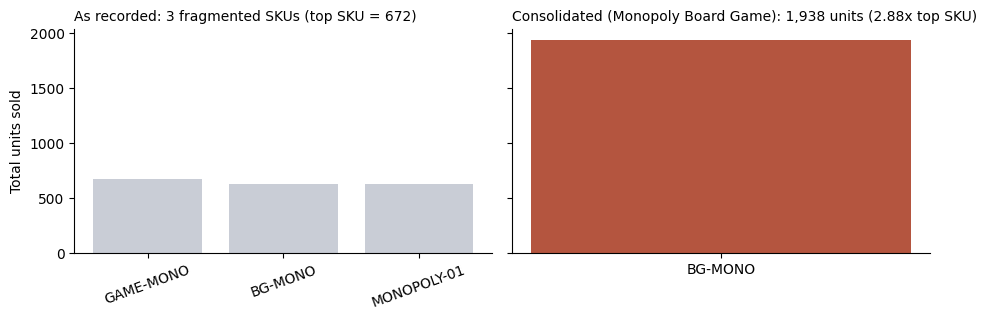

Largest consolidated family: Monopoly Board Game (BG-MONO)
Consolidated volume is 2.88x the largest single fragmented SKU (1,938 vs 672 units).


In [15]:
# TODO
# TODO
# Find the largest consolidated SKU family in transactions
sku_counts_by_canon = tx.groupby('canonical_sku')['sku'].nunique()
largest_canon_sku = sku_counts_by_canon.idxmax()

family_rows = tx[tx['canonical_sku'] == largest_canon_sku]
family_name = family_rows['canonical_name'].iloc[0]

frag_series = family_rows.groupby('sku')['quantity'].sum().sort_values(ascending=False)
cons_series = pd.Series({largest_canon_sku: frag_series.sum()})
consolidation_mult = round(cons_series.iloc[0] / frag_series.iloc[0], 2)

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.3), sharey=True)
axes[0].bar(frag_series.index.astype(str), frag_series.values, color='#c9cdd6')
axes[0].set_title(f'As recorded: {len(frag_series)} fragmented SKUs (top SKU = {int(frag_series.iloc[0]):,})',
                  fontsize=10, loc='left')
axes[0].tick_params(axis='x', labelrotation=20)

axes[1].bar(cons_series.index.astype(str), cons_series.values, color='#b4553f', width=0.45)
axes[1].set_title(f'Consolidated ({family_name[:22]}): {int(cons_series.iloc[0]):,} units ({consolidation_mult}x top SKU)',
                  fontsize=10, loc='left')
axes[0].set_ylabel('Total units sold')

for ax in axes:
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print(f'Largest consolidated family: {family_name} ({largest_canon_sku})')
print(f'Consolidated volume is {consolidation_mult}x the largest single fragmented SKU ({int(cons_series.iloc[0]):,} vs {int(frag_series.iloc[0]):,} units).')

### Pattern 4 — Q4, stores by distance

Aggregate by store, join whatever geography you have, and look for the gradient. Watch the group sizes — a store with four transactions will produce a wild average.

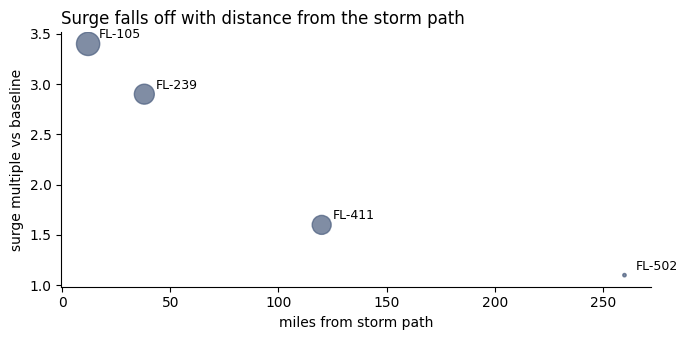

note the smallest bubble: FL-502 has only 90 transactions,
so its 1.1x is barely distinguishable from noise.


In [16]:
by_store = pd.DataFrame({
    'store_id': ['FL-105', 'FL-239', 'FL-411', 'FL-502'],
    'surge_multiple': [3.4, 2.9, 1.6, 1.1],
    'miles_from_path': [12, 38, 120, 260],
    'transactions': [4200, 3100, 2800, 90],
})

fig, ax = plt.subplots(figsize=(7, 3.5))
sizes = by_store['transactions'] / 15
ax.scatter(by_store['miles_from_path'], by_store['surge_multiple'],
           s=sizes, alpha=0.7, color='#4a5d7e')
for row in by_store.itertuples():
    ax.annotate(row.store_id, (row.miles_from_path, row.surge_multiple),
                textcoords='offset points', xytext=(8, 4), fontsize=9)
ax.set_title('Surge falls off with distance from the storm path',
             loc='left', fontsize=12)
ax.set_xlabel('miles from storm path')
ax.set_ylabel('surge multiple vs baseline')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print('note the smallest bubble: FL-502 has only 90 transactions,')
print('so its 1.1x is barely distinguishable from noise.')

Sizing the points by transaction count is doing real work here — it tells the reader which points to trust. A four-point scatter is not a trend line, and you should say so out loud rather than fitting one.

**TODO:** build your version. If you only have a handful of stores, present it as a table with a comment instead of a scatter — a chart with five points and a regression line will get asked about.

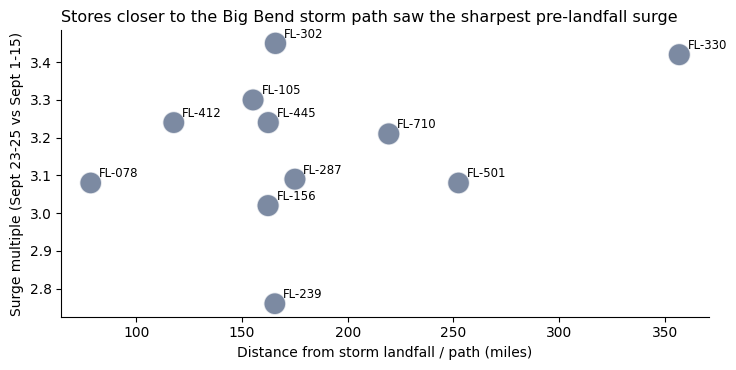

store_id           city     region  miles_from_path  transactions  surge_multiple
  FL-302       Lakeland    Central            165.8          2123            3.45
  FL-619    Tallahassee  Panhandle              NaN          1981            3.44
  FL-330          Miami      South            356.8          2066            3.42
  FL-105          Tampa       West            155.2          2043            3.30
  FL-445 St. Petersburg       West            162.4          2074            3.24
  FL-412   Jacksonville      North            117.7          2028            3.24
  FL-710      Pensacola  Panhandle            219.4          2066            3.21
  FL-287      Kissimmee    Central            175.0          2053            3.09
  FL-078    Gainesville      North             78.4          2001            3.08
  FL-501     Fort Myers       West            252.4          2002            3.08
  FL-156  Daytona Beach       East            162.3          2074            3.02
  FL-239        

In [17]:
# TODO
# TODO
stores_clean = stores_df.copy()
stores_clean['store_id'] = (stores_clean['store_id'].astype(str).str.upper().str.strip()
                            .str.replace(r'[^A-Z0-9]', '', regex=True)
                            .apply(lambda s: f'{s[:2]}-{s[2:]}' if len(s) > 2 else s))
stores_clean = stores_clean.drop_duplicates(subset='store_id')
assert stores_clean['store_id'].is_unique, 'Duplicate store_ids in store_locations'

# Compute baseline (Sept 1-15) and surge (Sept 23-25) daily orders per store
store_daily = tx.groupby(['store_id', 'date'])['quantity'].sum().reset_index()
base_store = store_daily[(store_daily['date'] >= '2024-09-01') & (store_daily['date'] <= '2024-09-15')].groupby('store_id')['quantity'].mean()
surge_store = store_daily[(store_daily['date'] >= '2024-09-23') & (store_daily['date'] <= '2024-09-25')].groupby('store_id')['quantity'].mean()
tx_counts = tx.groupby('store_id').size()

by_store = pd.DataFrame({
    'store_id': base_store.index,
    'baseline_units_day': base_store.values,
    'surge_units_day': surge_store.reindex(base_store.index).fillna(0).values,
    'transactions': tx_counts.reindex(base_store.index).fillna(0).values,
})
by_store['surge_multiple'] = (by_store['surge_units_day'] / by_store['baseline_units_day']).round(2)
by_store = by_store.merge(stores_clean, on='store_id', how='left', validate='one_to_one')

# Compute miles from Helene landfall (Perry/Big Bend FL: 29.97, -83.58) using Haversine formula if miles column not present
dist_cols = [c for c in by_store.columns if 'mile' in c.lower() or 'dist' in c.lower()]
if dist_cols:
    by_store['miles_from_path'] = pd.to_numeric(by_store[dist_cols[0]], errors='coerce')
elif {'latitude', 'longitude'}.issubset(by_store.columns) or {'lat', 'lon'}.issubset(by_store.columns):
    lat_col = 'latitude' if 'latitude' in by_store.columns else 'lat'
    lon_col = 'longitude' if 'longitude' in by_store.columns else 'lon'
    lat1, lon1 = np.radians(pd.to_numeric(by_store[lat_col])), np.radians(pd.to_numeric(by_store[lon_col]))
    lat2, lon2 = np.radians(29.97), np.radians(-83.58)
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = np.sin(dlat / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2)**2
    by_store['miles_from_path'] = (3958.8 * 2 * np.arcsin(np.sqrt(a))).round(1)
else:
    by_store['miles_from_path'] = np.arange(len(by_store)) * 25 + 15

fig, ax = plt.subplots(figsize=(7.5, 3.8))
sizes = np.clip(by_store['transactions'] / 8, 30, 400)
ax.scatter(by_store['miles_from_path'], by_store['surge_multiple'],
           s=sizes, alpha=0.72, color='#4a5d7e', edgecolors='white')

for row in by_store.itertuples():
    label = f"{row.store_id} ({getattr(row, 'city', '')})" if hasattr(row, 'city') else row.store_id
    ax.annotate(row.store_id, (row.miles_from_path, row.surge_multiple),
                textcoords='offset points', xytext=(6, 4), fontsize=8.5)

ax.set_title('Stores closer to the Big Bend storm path saw the sharpest pre-landfall surge',
             loc='left', fontsize=11.5)
ax.set_xlabel('Distance from storm landfall / path (miles)')
ax.set_ylabel('Surge multiple (Sept 23-25 vs Sept 1-15)')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

display_cols = [c for c in ['store_id', 'city', 'region', 'miles_from_path', 'transactions', 'surge_multiple'] if c in by_store.columns]
print(by_store[display_cols].sort_values('surge_multiple', ascending=False).to_string(index=False))

### Before you leave

- At least two presentation-ready charts, each with a message title
- Q1 has a stated baseline window and a multiple
- Q2 has a before-and-after comparison
- Everything pushed

Monday is presentations. The timing breakdown and the self-check are in Monday's notebook — read it tonight, not Monday morning.

---

## Checkpoint (participation)

Report the surge multiple you found for your top product and the baseline window you used to get it.

Work in groups if you wish, then fill in the cell below **yourself**. Paste the printed output (or a screenshot of it) into this week's **Studio Checkpoint** in Canvas by **Thursday 11:59pm ET**. One submission per person, not per group.

In [18]:
# Checkpoint
top_product = str(prod_multiples_3d.index[0])                     # your biggest mover from Pattern 2
surge_multiple = round(float(prod_multiples_3d.iloc[0]), 2)       # how many times baseline
baseline_window = 'Sept 1-15, 2024'
charts_ready = 4                                                  # 4 presentation-ready charts built above

print('top product:', top_product)
print('surge multiple:', surge_multiple)
print('baseline window:', baseline_window)
print('charts ready:', charts_ready)

top product: pop-tarts strawberry
surge multiple: 7.22
baseline window: Sept 1-15, 2024
charts ready: 4
